In [1]:
#checking model
import pandas as pd
import numpy as np
import sklearn
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("sklearn", sklearn.__version__)

pandas 3.0.5
numpy 2.5.2
sklearn 1.9.0


In [2]:
#downloading data set
import urllib.request
import os

os.makedirs('data', exist_ok=True)

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
urllib.request.urlretrieve(url, 'data/heart.csv')

print("Downloaded!")
print(os.listdir('data'))

Downloaded!
['heart.csv']


In [3]:
import pandas as pd

cols = ['age','sex','cp','trestbps','chol','fbs','restecg',
        'thalach','exang','oldpeak','slope','ca','thal','target']

df = pd.read_csv('data/heart.csv', names=cols, na_values='?')

print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (303, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
#check missing values
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [5]:
#drop the rows
print("Before dropping:", df.shape)
df = df.dropna()
print("After dropping:", df.shape)

Before dropping: (303, 14)
After dropping: (297, 14)


In [6]:
print("Original target values:")
print(df['target'].value_counts().sort_index())

#collapse 1-4 to 1
df['target'] = (df['target'] > 0).astype(int)

print("\nAfter binarizing:")
print(df['target'].value_counts())

Original target values:
target
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

After binarizing:
target
0    160
1    137
Name: count, dtype: int64


In [7]:
#shape check
df.info()

<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  target    297 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 34.8 KB


In [8]:
from sklearn.model_selection import train_test_split

#step 1: separate test set (20%)
X = df.drop('target', axis=1)
y = df['target']

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#step 2: split temp into train (75%) and val (25%) to 60/20 overall
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp
)

print("Train:", X_train.shape, "Disease %:", round(y_train.mean()*100, 1))
print("Val:  ", X_val.shape,   "Disease %:", round(y_val.mean()*100, 1))
print("Test: ", X_test.shape,  "Disease %:", round(y_test.mean()*100, 1))

Train: (177, 13) Disease %: 45.8
Val:   (60, 13) Disease %: 46.7
Test:  (60, 13) Disease %: 46.7


In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

##predict on train and validation + ccale features: mean=0, std=1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

#retrain due to features being different scale 
lr = LogisticRegression(max_iter=5000, random_state=42)
lr.fit(X_train_scaled, y_train)

#predict on train and validation
train_pred = lr.predict(X_train_scaled)
val_pred   = lr.predict(X_val_scaled)

#compare
print("Train accuracy:", round(accuracy_score(y_train, train_pred) * 100, 1))
print("Val accuracy:  ", round(accuracy_score(y_val, val_pred) * 100, 1))
print()
print(classification_report(y_val, val_pred, target_names=['No Disease', 'Disease']))

Train accuracy: 85.9
Val accuracy:   81.7

              precision    recall  f1-score   support

  No Disease       0.82      0.84      0.83        32
     Disease       0.81      0.79      0.80        28

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.82        60
weighted avg       0.82      0.82      0.82        60



In [10]:
#NOTE: accuracy reduced from 83.3% to 81.7% due to convergence warning for stability
print("Train rows:", X_train.shape)
print("Val rows:  ", X_val.shape)
print("Test rows: ", X_test.shape)
print("Scaled arrays exist:", 'X_train_scaled' in dir())

Train rows: (177, 13)
Val rows:   (60, 13)
Test rows:  (60, 13)
Scaled arrays exist: True


In [11]:


# ============================================================
#BASELINE MODEL: logistic regression
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

#scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

#train
lr = LogisticRegression(max_iter=5000, random_state=42)
lr.fit(X_train_scaled, y_train)

#evaluate
train_pred = lr.predict(X_train_scaled)
val_pred   = lr.predict(X_val_scaled)

print("Logistic Regression Baseline")
print("=" * 40)
print(f"Train accuracy: {accuracy_score(y_train, train_pred)*100:.1f}%")
print(f"Val accuracy:   {accuracy_score(y_val, val_pred)*100:.1f}%")
print()
print(classification_report(y_val, val_pred, target_names=['No Disease', 'Disease']))

Logistic Regression Baseline
Train accuracy: 85.9%
Val accuracy:   81.7%

              precision    recall  f1-score   support

  No Disease       0.82      0.84      0.83        32
     Disease       0.81      0.79      0.80        28

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.82        60
weighted avg       0.82      0.82      0.82        60



In [12]:
# ============================================================
#MODEL 2: decision tree
# ============================================================
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)   # No scaling needed for trees

dt_train_pred = dt.predict(X_train)
dt_val_pred   = dt.predict(X_val)

print("Decision Tree")
print("=" * 40)
print(f"Train accuracy: {accuracy_score(y_train, dt_train_pred)*100:.1f}%")
print(f"Val accuracy:   {accuracy_score(y_val, dt_val_pred)*100:.1f}%")
print()

# ============================================================
#MODEL 3: random forest
# ============================================================
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=500, random_state=42)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict(X_train)
rf_val_pred   = rf.predict(X_val)

print("Random Forest")
print("=" * 40)
print(f"Train accuracy: {accuracy_score(y_train, rf_train_pred)*100:.1f}%")
print(f"Val accuracy:   {accuracy_score(y_val, rf_val_pred)*100:.1f}%")

Decision Tree
Train accuracy: 100.0%
Val accuracy:   76.7%

Random Forest
Train accuracy: 100.0%
Val accuracy:   75.0%


In [13]:
#limit tree depth
dt = DecisionTreeClassifier(max_depth=4, random_state=42)

In [14]:
# ============================================================
#MODEL 2b: decision tree with depth tuning
# ============================================================
from sklearn.tree import DecisionTreeClassifier

print("Depth | Train Acc | Val Acc")
print("-" * 35)

for depth in [2, 3, 4, 5, 6, 7, 8, 10, None]:
    dt_tuned = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt_tuned.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, dt_tuned.predict(X_train)) * 100
    val_acc   = accuracy_score(y_val,   dt_tuned.predict(X_val)) * 100

    depth_str = "None" if depth is None else str(depth)
    print(f"{depth_str:>5} | {train_acc:>8.1f}% | {val_acc:>6.1f}%")

Depth | Train Acc | Val Acc
-----------------------------------
    2 |     78.5% |   71.7%
    3 |     89.8% |   78.3%
    4 |     92.1% |   76.7%
    5 |     97.7% |   76.7%
    6 |     98.9% |   71.7%
    7 |     99.4% |   70.0%
    8 |    100.0% |   76.7%
   10 |    100.0% |   76.7%
 None |    100.0% |   76.7%


In [15]:
#NOTES:
#Depth 2 = underfitting. Too simple, val acc only 71.7%
#Depth 3 = sweet spot. 78.3% — the peak
#Depth 4–5 = starting to overfit. Val stops improving, train keeps climbing
#Depth 6+ = fully overfit. Val drops, gap is huge
#Depth 8+ = train hits 100%. Model memorizes but doesn't generalize

In [16]:
# ============================================================
#MODEL 3b: random forest with depth tuning
# ============================================================
from sklearn.ensemble import RandomForestClassifier

print("Depth | Train Acc | Val Acc")
print("-" * 35)

for depth in [2, 3, 4, 5, 6, 8, 10, None]:
    rf_tuned = RandomForestClassifier(
        n_estimators=500, max_depth=depth, random_state=42
    )
    rf_tuned.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, rf_tuned.predict(X_train)) * 100
    val_acc   = accuracy_score(y_val,   rf_tuned.predict(X_val)) * 100

    depth_str = "None" if depth is None else str(depth)
    print(f"{depth_str:>5} | {train_acc:>8.1f}% | {val_acc:>6.1f}%")

Depth | Train Acc | Val Acc
-----------------------------------
    2 |     87.6% |   78.3%
    3 |     89.3% |   78.3%
    4 |     91.5% |   80.0%
    5 |     96.6% |   75.0%
    6 |     99.4% |   75.0%
    8 |    100.0% |   78.3%
   10 |    100.0% |   76.7%
 None |    100.0% |   75.0%


In [17]:
# ============================================================
#PIPELINE: scaler + logistic regression in one object
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LogisticRegression(max_iter=5000, random_state=42))
])

# Fit on RAW train data - pipeline handles scaling internally
pipe.fit(X_train, y_train)

# Predict on RAW val data
train_pred = pipe.predict(X_train)
val_pred   = pipe.predict(X_val)

print("Pipeline: Logistic Regression")
print("=" * 40)
print(f"Train accuracy: {accuracy_score(y_train, train_pred)*100:.1f}%")
print(f"Val accuracy:   {accuracy_score(y_val,   val_pred)*100:.1f}%")

Pipeline: Logistic Regression
Train accuracy: 85.9%
Val accuracy:   81.7%


In [18]:
# ============================================================
#CROSS-VALIDATION: compare 3 models on train+val
# ============================================================
import numpy as np
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

#combine train + val (test set stays locked)
X_cv = pd.concat([X_train, X_val], axis=0)
y_cv = pd.concat([y_train, y_val], axis=0)

print(f"CV data shape: {X_cv.shape}")
print()

#define the three models as pipelines
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=5000, random_state=42))
    ]),
    'Decision Tree (d=3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Random Forest (d=4)': RandomForestClassifier(
        n_estimators=500, max_depth=4, random_state=42
    ),
}

#run 5-fold CV for each
print(f"{'Model':<25} {'Mean Acc':>10} {'Std':>8}")
print("-" * 45)

for name, model in models.items():
    scores = cross_val_score(model, X_cv, y_cv, cv=5, scoring='accuracy')
    print(f"{name:<25} {scores.mean()*100:>9.1f}% {scores.std()*100:>7.1f}%")

CV data shape: (237, 13)

Model                       Mean Acc      Std
---------------------------------------------
Logistic Regression            81.4%     6.4%
Decision Tree (d=3)            79.3%     3.8%
Random Forest (d=4)            84.4%     7.3%


In [20]:
# ============================================================
#FINAL EVALUATION: test set (used ONCE)
# ============================================================
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- random forest (best CV accuracy) ---
rf_pipe = Pipeline([
    ('model', RandomForestClassifier(n_estimators=500, max_depth=4, random_state=42))
])
rf_pipe.fit(X_cv, y_cv)
rf_test_pred = rf_pipe.predict(X_test)

print("=" * 50)
print("RANDOM FOREST (depth=4) — TEST SET")
print("=" * 50)
print(f"Test accuracy: {accuracy_score(y_test, rf_test_pred)*100:.1f}%")
print(classification_report(y_test, rf_test_pred, target_names=['No Disease', 'Disease']))
print("Confusion matrix:")
print(confusion_matrix(y_test, rf_test_pred))
print()

# --- logistic regression (baseline comparison) ---
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LogisticRegression(max_iter=5000, random_state=42))
])
lr_pipe.fit(X_cv, y_cv)
lr_test_pred = lr_pipe.predict(X_test)

print("=" * 50)
print("LOGISTIC REGRESSION — TEST SET")
print("=" * 50)
print(f"Test accuracy: {accuracy_score(y_test, lr_test_pred)*100:.1f}%")
print(classification_report(y_test, lr_test_pred, target_names=['No Disease', 'Disease']))
print("Confusion matrix:")
print(confusion_matrix(y_test, lr_test_pred))

RANDOM FOREST (depth=4) — TEST SET
Test accuracy: 83.3%
              precision    recall  f1-score   support

  No Disease       0.79      0.94      0.86        32
     Disease       0.91      0.71      0.80        28

    accuracy                           0.83        60
   macro avg       0.85      0.83      0.83        60
weighted avg       0.85      0.83      0.83        60

Confusion matrix:
[[30  2]
 [ 8 20]]

LOGISTIC REGRESSION — TEST SET
Test accuracy: 83.3%
              precision    recall  f1-score   support

  No Disease       0.82      0.88      0.85        32
     Disease       0.85      0.79      0.81        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60

Confusion matrix:
[[28  4]
 [ 6 22]]


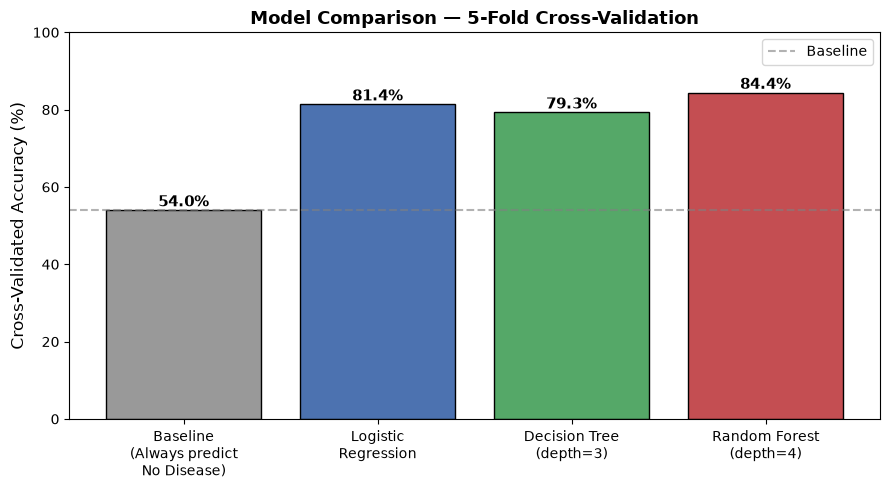

In [21]:
# ============================================================
#CHART 1: model comparison
# ============================================================
import matplotlib.pyplot as plt

models = ['Baseline\n(Always predict\nNo Disease)', 'Logistic\nRegression', 'Decision Tree\n(depth=3)', 'Random Forest\n(depth=4)']
scores = [54.0, 81.4, 79.3, 84.4]   # CV numbers (fair comparison)
colors = ['#999999', '#4C72B0', '#55A868', '#C44E52']

plt.figure(figsize=(9, 5))
bars = plt.bar(models, scores, color=colors, edgecolor='black')

for bar, score in zip(bars, scores):
    plt.text(bar.get_x() + bar.get_width()/2, score + 1,
             f'{score:.1f}%', ha='center', fontsize=11, fontweight='bold')

plt.ylabel('Cross-Validated Accuracy (%)', fontsize=12)
plt.title('Model Comparison — 5-Fold Cross-Validation', fontsize=13, fontweight='bold')
plt.ylim(0, 100)
plt.axhline(y=54, color='gray', linestyle='--', alpha=0.6, label='Baseline')
plt.legend()
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

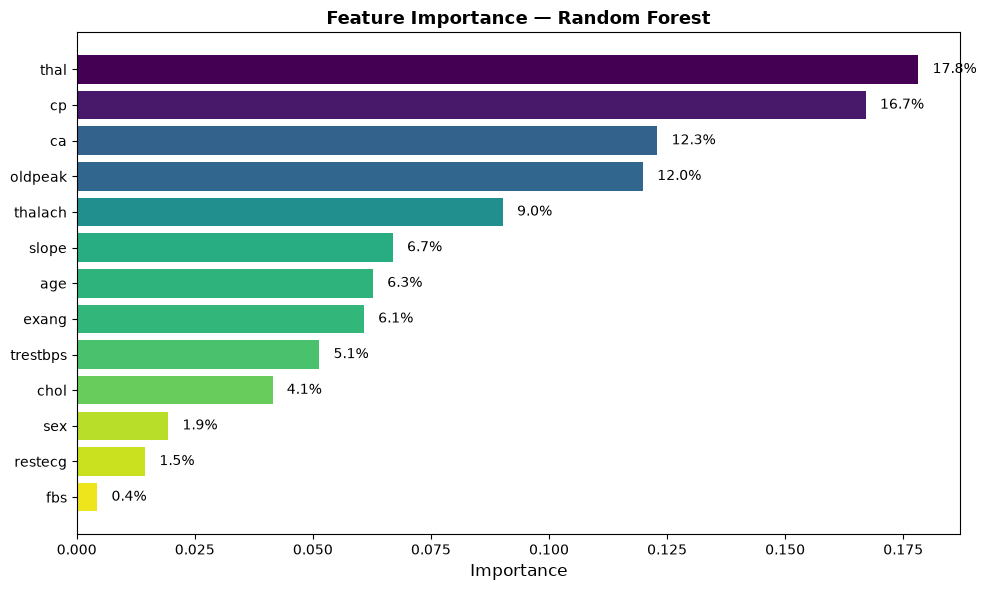

In [22]:
# ============================================================
#CHART 3: feature importance (from random forest)
# ============================================================
import pandas as pd

#fit a random forest on all train+val data for feature importance
rf_fi = RandomForestClassifier(n_estimators=500, max_depth=4, random_state=42)
rf_fi.fit(X_cv, y_cv)

importance = pd.DataFrame({
    'feature': X_cv.columns,
    'importance': rf_fi.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
bars = plt.barh(importance['feature'], importance['importance'],
                color=plt.cm.viridis_r(importance['importance'] / importance['importance'].max()))
plt.xlabel('Importance', fontsize=12)
plt.title('Feature Importance — Random Forest', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()

for bar, val in zip(bars, importance['importance']):
    plt.text(val + 0.003, bar.get_y() + bar.get_height()/2,
             f'{val:.1%}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()